# A Reproducible Machine-Learning Benchmark for Cancer Classification

## 1. Research Question and Objectives

**Research question:** How do different machine-learning models compare in classifying malignant and benign breast tumours, and does tuning for malignant tumour detection improve performance?

This project uses the Wisconsin Breast Cancer Diagnostic dataset to compare Logistic Regression, Support Vector Machine (SVM), and Random Forest models.

**Objectives**
- Explore the dataset, class distribution, and feature relationships.
- Establish baseline models and compare their performance.
- Evaluate models using stratified cross-validation and a held-out test set.
- Investigate whether hyperparameter tuning improves malignant tumour detection.
- Examine classification errors and discuss the limitations of the results.

**Evaluation priority:** Malignant recall is important because false negatives matter, but it must be considered alongside precision, accuracy, and other performance metrics.

In [1]:
# Standard library
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset and data splitting
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
# Pipelines and preprocessing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# Machine-learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    make_scorer,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Dataset Loading and Exploration

In [2]:
# Load the Wisconsin Breast Cancer Diagnostic dataset
data = load_breast_cancer()

# Separate feature measurements from diagnosis labels
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="diagnosis")

print("Number of samples and features:", X.shape)
print("Number of diagnosis labels:", y.shape)

Number of samples and features: (569, 30)
Number of diagnosis labels: (569,)


In [3]:
print("Target names:", data.target_names)
print("\nLabel encoding:")
print("0 =", data.target_names[0])
print("1 =", data.target_names[1])

print("\nDiagnosis counts:")
print(y.value_counts())

Target names: ['malignant' 'benign']

Label encoding:
0 = malignant
1 = benign

Diagnosis counts:
diagnosis
1    357
0    212
Name: count, dtype: int64


In [4]:
# Check for missing values
print("Missing values per column:")
print(X.isnull().sum().sum())

# Inspect the feature measurements
print("\nSummary statistics:")
display(X.describe().round(2))

Missing values per column:
0

Summary statistics:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21


In [5]:
print("Features with the smallest means:")
print(X.mean().sort_values().head(5).round(3))

print("\nFeatures with the largest means:")
print(X.mean().sort_values(ascending=False).head(5).round(3))

Features with the smallest means:
fractal dimension error    0.004
smoothness error           0.007
concave points error       0.012
symmetry error             0.021
compactness error          0.025
dtype: float64

Features with the largest means:
worst area         880.583
mean area          654.889
worst perimeter    107.261
mean perimeter      91.969
area error          40.337
dtype: float64


In [6]:
# Calculate correlations between numerical features
correlations = X.corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = correlations.where(
    np.triu(np.ones(correlations.shape), k=1).astype(bool)
)

# Find the 10 most strongly correlated feature pairs
top_correlations = (
    upper_triangle.stack()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 most strongly correlated feature pairs:")
display(top_correlations)

Top 10 most strongly correlated feature pairs:


mean radius      mean perimeter     0.997855
worst radius     worst perimeter    0.993708
mean radius      mean area          0.987357
mean perimeter   mean area          0.986507
worst radius     worst area         0.984015
worst perimeter  worst area         0.977578
radius error     perimeter error    0.972794
mean perimeter   worst perimeter    0.970387
mean radius      worst radius       0.969539
mean perimeter   worst radius       0.969476
dtype: float64

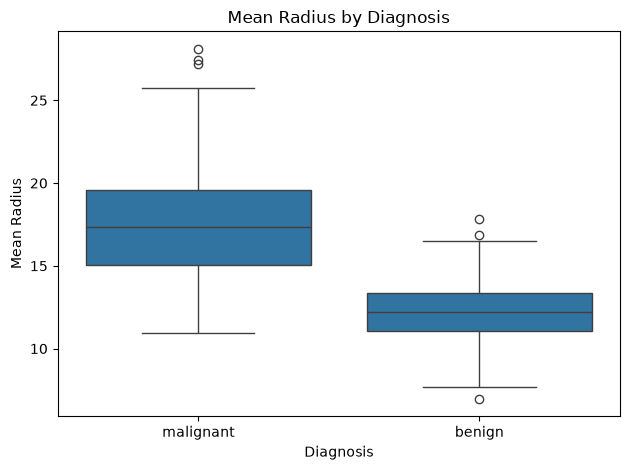

In [7]:
# Add diagnosis labels for visualisation
plot_data = X.copy()
plot_data["diagnosis"] = y.map({
    0: "malignant",
    1: "benign"
})

# Compare mean radius between diagnoses
sns.boxplot(
    data=plot_data,
    x="diagnosis",
    y="mean radius"
)

plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.tight_layout()
plt.show()

In [8]:
print(
    plot_data.groupby("diagnosis")["mean radius"]
    .describe()
    .round(2)
)

           count   mean   std    min    25%    50%    75%    max
diagnosis                                                       
benign     357.0  12.15  1.78   6.98  11.08  12.20  13.37  17.85
malignant  212.0  17.46  3.20  10.95  15.08  17.33  19.59  28.11


In [9]:
print(
    plot_data.groupby("diagnosis")["mean texture"]
    .describe()
    .round(2)
)

           count   mean   std    min    25%    50%    75%    max
diagnosis                                                       
benign     357.0  17.91  4.00   9.71  15.15  17.39  19.76  33.81
malignant  212.0  21.60  3.78  10.38  19.33  21.46  23.76  39.28


Diagnosis counts:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64

Diagnosis percentages:
diagnosis
benign       62.74
malignant    37.26
Name: proportion, dtype: float64


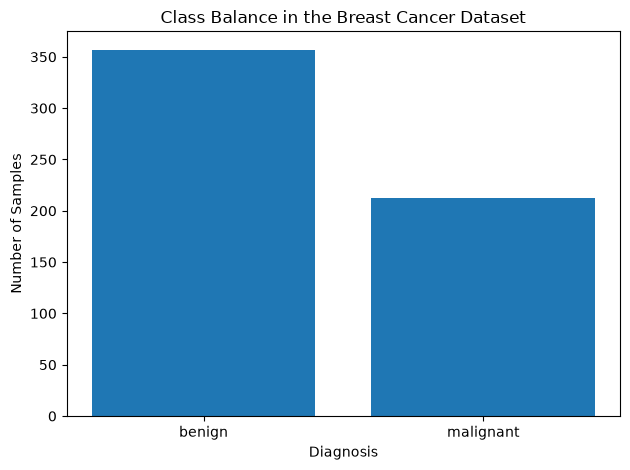

In [10]:
# Count samples in each diagnosis group
diagnosis_counts = plot_data["diagnosis"].value_counts()

# Calculate percentages
diagnosis_percentages = (
    plot_data["diagnosis"].value_counts(normalize=True) * 100
)

print("Diagnosis counts:")
print(diagnosis_counts)

print("\nDiagnosis percentages:")
print(diagnosis_percentages.round(2))

# Visualise class balance
plt.bar(diagnosis_counts.index, diagnosis_counts.values)

plt.title("Class Balance in the Breast Cancer Dataset")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

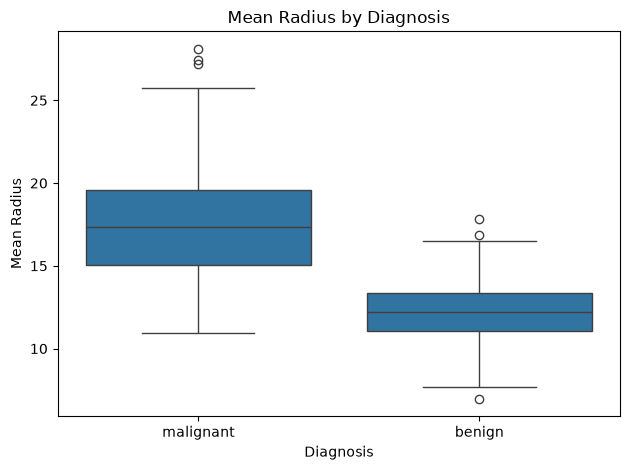

In [11]:
# Compare mean radius between diagnosis groups
sns.boxplot(data=plot_data, x="diagnosis", y="mean radius")

plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.tight_layout()
plt.show()

## 3. Train/Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert numerical labels into readable diagnosis names
label_names = {0: "malignant", 1: "benign"}

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

print("\nTraining diagnosis proportions:")
print(y_train.map(label_names).value_counts(normalize=True).round(3))

print("\nTest diagnosis proportions:")
print(y_test.map(label_names).value_counts(normalize=True).round(3))

Training samples: 455
Test samples: 114

Training diagnosis proportions:
diagnosis
benign       0.626
malignant    0.374
Name: proportion, dtype: float64

Test diagnosis proportions:
diagnosis
benign       0.632
malignant    0.368
Name: proportion, dtype: float64


## 4. Baseline Model Setup and Evaluation

In [13]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=42))
])

print("Logistic regression pipeline created successfully!")

Logistic regression pipeline created successfully!


In [14]:
logistic_pipeline.fit(X_train, y_train)

print("Logistic regression trained successfully!")

Logistic regression trained successfully!


In [15]:
# Predict diagnosis labels for the held-out test set
y_pred = logistic_pipeline.predict(X_test)

# Estimate the probability of the malignant class (label 0)
y_prob_malignant = logistic_pipeline.predict_proba(X_test)[:, 0]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(
    (y_test == 0).astype(int),
    y_prob_malignant
), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["malignant", "benign"],
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy: 0.9825
ROC-AUC: 0.9954

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion matrix (rows = actual, columns = predicted):
[[41  1]
 [ 1 71]]


In [16]:
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

print("SVM pipeline created!")
print("Random forest pipeline created!")

SVM pipeline created!
Random forest pipeline created!


In [17]:
# Collect the three baseline pipelines in one place
models = {
    "Logistic Regression": logistic_pipeline,
    "SVM": svm_pipeline,
    "Random Forest": rf_pipeline
}

# Fit each baseline model on the training set for test-set and error analysis
for name, model in models.items():
    model.fit(X_train, y_train)

print("All three baseline models fitted successfully.")

C:\Users\Kazha\OneDrive\Dokumenty\cancer-ml-benchmark\.venv313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


All three baseline models fitted successfully.


## 5. Stratified Cross-Validation

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Five-fold stratified cross-validation is ready.")

Five-fold stratified cross-validation is ready.


In [19]:
scoring = {
    "accuracy": "accuracy",
    "malignant_recall": make_scorer(recall_score, pos_label=0),
    "roc_auc": "roc_auc"
}
cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy SD": scores["test_accuracy"].std(),
        "CV Malignant Recall Mean": scores["test_malignant_recall"].mean(),
        "CV ROC-AUC Mean": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)
print(cv_df.round(4).to_string(index=False))           

              Model  CV Accuracy Mean  CV Accuracy SD  CV Malignant Recall Mean  CV ROC-AUC Mean
Logistic Regression            0.9780          0.0098                    0.9647           0.9959
                SVM            0.9692          0.0146                    0.9529           0.9956
      Random Forest            0.9538          0.0146                    0.9529           0.9916


In [20]:
results_dir = Path("../Results")
results_dir.mkdir(parents=True, exist_ok=True)

cv_df.to_csv(
    results_dir / "cross_validation_results.csv",
    index=False
)

print("Cross-validation results saved!")
print("File:", results_dir / "cross_validation_results.csv")

Cross-validation results saved!
File: ..\Results\cross_validation_results.csv


## 6. Logistic Regression Hyperparameter Tuning

In [21]:
# Tune using training data only
tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

malignant_recall_scorer = make_scorer(
    recall_score,
    pos_label=0
)

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring=malignant_recall_scorer,
    cv=tuning_cv,
    n_jobs=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(
    "Best cross-validated malignant recall:",
    round(grid_search.best_score_, 4)
)

Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best cross-validated malignant recall: 0.9765


In [22]:
tuned_model = grid_search.best_estimator_

y_pred_tuned = tuned_model.predict(X_test)

# Probability for class 0 (malignant)
y_prob_malignant = tuned_model.predict_proba(X_test)[
    :, list(tuned_model.classes_).index(0)
]

print("Tuned Logistic Regression — Test Set")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print(
    "Malignant recall:",
    round(recall_score(y_test, y_pred_tuned, pos_label=0), 4)
)
print(
    "Malignant precision:",
    round(precision_score(y_test, y_pred_tuned, pos_label=0), 4)
)
print(
    "Malignant F1:",
    round(f1_score(y_test, y_pred_tuned, pos_label=0), 4)
)
    
print(
    "ROC-AUC:",
    round(roc_auc_score((y_test == 0).astype(int), y_prob_malignant), 4)
)

Tuned Logistic Regression — Test Set
Accuracy: 0.9561
Malignant recall: 0.9762
Malignant precision: 0.9111
Malignant F1: 0.9425
ROC-AUC: 0.9954


In [23]:

baseline_metrics = {
    "Model": "Logistic Regression (baseline)",
    "Accuracy": accuracy_score(y_test, models["Logistic Regression"].predict(X_test)),
    "Malignant Recall": recall_score(
        y_test, models["Logistic Regression"].predict(X_test), pos_label=0
    ),
    "Malignant Precision": precision_score(
        y_test, models["Logistic Regression"].predict(X_test), pos_label=0
    ),
    "Malignant F1": f1_score(
        y_test, models["Logistic Regression"].predict(X_test), pos_label=0
    ),
    "ROC-AUC": roc_auc_score(
        (y_test == 0).astype(int),
        models["Logistic Regression"].predict_proba(X_test)[
            :, list(models["Logistic Regression"].classes_).index(0)
        ]
    )
}

tuned_metrics = {
    "Model": "Logistic Regression (tuned)",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Malignant Recall": recall_score(y_test, y_pred_tuned, pos_label=0),
    "Malignant Precision": precision_score(y_test, y_pred_tuned, pos_label=0),
    "Malignant F1": f1_score(y_test, y_pred_tuned, pos_label=0),
    "ROC-AUC": roc_auc_score(
        (y_test == 0).astype(int), y_prob_malignant
    )
}

comparison_df = pd.DataFrame([baseline_metrics, tuned_metrics])

comparison_path = Path("../Results/logistic_regression_tuning_comparison.csv")
comparison_df.to_csv(comparison_path, index=False)

print(comparison_df.round(4).to_string(index=False))
print("\nSaved:", comparison_path.resolve())


                         Model  Accuracy  Malignant Recall  Malignant Precision  Malignant F1  ROC-AUC
Logistic Regression (baseline)    0.9825            0.9762               0.9762        0.9762   0.9954
   Logistic Regression (tuned)    0.9561            0.9762               0.9111        0.9425   0.9954

Saved: C:\Users\Kazha\OneDrive\Dokumenty\cancer-ml-benchmark\Results\logistic_regression_tuning_comparison.csv


## 7. Test-Set Error Analysis

In [24]:
baseline_model = models["Logistic Regression"]

baseline_pred = baseline_model.predict(X_test)
tuned_pred = tuned_model.predict(X_test)

errors_df = pd.DataFrame({
    "Actual": y_test.map({0: "malignant", 1: "benign"}),
    "Baseline prediction": pd.Series(
        baseline_pred, index=y_test.index
    ).map({0: "malignant", 1: "benign"}),
    "Tuned prediction": pd.Series(
        tuned_pred, index=y_test.index
    ).map({0: "malignant", 1: "benign"}),
    "Baseline P(malignant)": baseline_model.predict_proba(
        X_test
    )[:, list(baseline_model.classes_).index(0)],
    "Tuned P(malignant)": tuned_model.predict_proba(
        X_test
    )[:, list(tuned_model.classes_).index(0)]
})

print("Benign cases flagged as malignant by the baseline:")
print(
    errors_df[
        (y_test == 1) & (baseline_pred == 0)
    ].round(3).to_string()
)

print("\nBenign cases flagged as malignant by the tuned model:")
print(
    errors_df[
        (y_test == 1) & (tuned_pred == 0)
    ].round(3).to_string()
)

Benign cases flagged as malignant by the baseline:
     Actual Baseline prediction Tuned prediction  Baseline P(malignant)  Tuned P(malignant)
541  benign           malignant        malignant                  0.634               0.687

Benign cases flagged as malignant by the tuned model:
     Actual Baseline prediction Tuned prediction  Baseline P(malignant)  Tuned P(malignant)
363  benign              benign        malignant                  0.466               0.547
541  benign           malignant        malignant                  0.634               0.687
542  benign              benign        malignant                  0.453               0.571
291  benign              benign        malignant                  0.463               0.559


In [25]:
features_to_inspect = [
    "mean radius",
    "mean perimeter",
    "mean area",
    "mean concavity",
    "mean concave points"
]

false_positive_indices = errors_df.index[
    (y_test == 1) & (tuned_pred == 0)
]

# Inspect these measurements for the flagged benign samples
flagged_samples = X_test.loc[
    false_positive_indices, features_to_inspect
]

print("Flagged benign samples:")
print(flagged_samples.round(3).to_string())

# Compare with the training-set distributions
comparison = pd.DataFrame({
    "Benign training median": X_train.loc[
        y_train == 1, features_to_inspect
    ].median(),
    "Malignant training median": X_train.loc[
        y_train == 0, features_to_inspect
    ].median()
})

print("\nTraining-set feature medians:")
print(comparison.round(3).to_string())

Flagged benign samples:
     mean radius  mean perimeter  mean area  mean concavity  mean concave points
363        16.50          106.60      838.1           0.059                0.048
541        14.47           95.81      656.4           0.101                0.039
542        14.74           94.70      668.6           0.041                0.030
291        14.96           97.03      687.3           0.059                0.048

Training-set feature medians:
                     Benign training median  Malignant training median
mean radius                          12.180                     17.195
mean perimeter                       78.070                    113.200
mean area                           453.100                    928.250
mean concavity                        0.035                      0.152
mean concave points                   0.023                      0.086


## 8. Nested Cross-Validation

In [26]:
outer_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)
inner_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=123
)

baseline_models = {
    "Logistic Regression (baseline)": logistic_pipeline,
    "SVM (baseline)": svm_pipeline,
    "Random Forest (baseline)": rf_pipeline
}

nested_rows = []

def record_metrics(name, y_true, y_pred, p_malignant):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Malignant Recall": recall_score(
            y_true, y_pred, pos_label=0
        ),
        "Malignant Precision": precision_score(
            y_true, y_pred, pos_label=0
        ),
        "Malignant F1": f1_score(
            y_true, y_pred, pos_label=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_true == 0).astype(int), p_malignant
        )
    }

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):
    X_outer_train = X_train.iloc[train_idx]
    X_outer_val = X_train.iloc[val_idx]
    y_outer_train = y_train.iloc[train_idx]
    y_outer_val = y_train.iloc[val_idx]

    # Evaluate each baseline model on this outer fold
    for name, model in baseline_models.items():
        fitted_model = clone(model)
        fitted_model.fit(X_outer_train, y_outer_train)

        predictions = fitted_model.predict(X_outer_val)
        malignant_col = list(fitted_model.classes_).index(0)
        probabilities = fitted_model.predict_proba(
            X_outer_val
        )[:, malignant_col]

        row = record_metrics(
            name, y_outer_val, predictions, probabilities
        )
        row["Fold"] = fold
        nested_rows.append(row)

    # Tune only within this outer fold's training data
    inner_search = GridSearchCV(
        estimator=logistic_pipeline,
        param_grid=param_grid,
        scoring=malignant_recall_scorer,
        cv=inner_cv,
        n_jobs=1,
        refit=True
    )
    inner_search.fit(X_outer_train, y_outer_train)

    tuned_fold_model = inner_search.best_estimator_
    tuned_predictions = tuned_fold_model.predict(X_outer_val)
    malignant_col = list(tuned_fold_model.classes_).index(0)
    tuned_probabilities = tuned_fold_model.predict_proba(
        X_outer_val
    )[:, malignant_col]

    row = record_metrics(
        "Logistic Regression (nested tuning)",
        y_outer_val,
        tuned_predictions,
        tuned_probabilities
    )
    row["Fold"] = fold
    nested_rows.append(row)

nested_results = pd.DataFrame(nested_rows)

metric_names = [
    "Accuracy", "Malignant Recall", "Malignant Precision",
    "Malignant F1", "ROC-AUC"
]

nested_summary = nested_results.groupby("Model")[metric_names].agg(
    ["mean", "std"]
)

print(nested_summary.round(4).to_string())

C:\Users\Kazha\OneDrive\Dokumenty\cancer-ml-benchmark\.venv313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Kazha\OneDrive\Dokumenty\cancer-ml-benchmark\.venv313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Kazha\OneDrive\Dokumenty\cancer-ml-benchmark\.venv313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Kazha\OneDrive\Dokumenty\cancer-ml-benchmark\.venv31

                                    Accuracy         Malignant Recall         Malignant Precision         Malignant F1         ROC-AUC        
                                        mean     std             mean     std                mean     std         mean     std    mean     std
Model                                                                                                                                         
Logistic Regression (baseline)        0.9780  0.0110           0.9647  0.0322              0.9770  0.0240       0.9703  0.0151  0.9959  0.0055
Logistic Regression (nested tuning)   0.9692  0.0197           0.9588  0.0335              0.9594  0.0321       0.9588  0.0264  0.9945  0.0054
Random Forest (baseline)              0.9538  0.0163           0.9529  0.0161              0.9267  0.0353       0.9394  0.0207  0.9916  0.0060
SVM (baseline)                        0.9692  0.0163           0.9529  0.0446              0.9649  0.0233       0.9583  0.0231  0.9956  0.0053

In [27]:
results_dir = Path("../Results")
results_dir.mkdir(parents=True, exist_ok=True)

nested_summary.to_csv(
    results_dir / "nested_cv_model_comparison.csv"
)

print("Saved:", results_dir / "nested_cv_model_comparison.csv")

Saved: ..\Results\nested_cv_model_comparison.csv


## 9. Final Held-Out Test-Set Comparison

In [28]:
final_models = {
    "Logistic Regression (baseline)": logistic_pipeline,
    "SVM (baseline)": svm_pipeline,
    "Random Forest (baseline)": rf_pipeline,
    "Logistic Regression (tuned)": grid_search.best_estimator_
}

test_rows = []

for name, model in final_models.items():
    # Fit using training data only
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)

    predictions = fitted_model.predict(X_test)
    malignant_col = list(fitted_model.classes_).index(0)
    malignant_probabilities = fitted_model.predict_proba(
        X_test
    )[:, malignant_col]

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Malignant Recall": recall_score(
            y_test, predictions, pos_label=0
        ),
        "Malignant Precision": precision_score(
            y_test, predictions, pos_label=0
        ),
        "Malignant F1": f1_score(
            y_test, predictions, pos_label=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == 0).astype(int),
            malignant_probabilities
        )
    })

final_test_results = pd.DataFrame(test_rows)

print(final_test_results.round(4).to_string(index=False))

final_test_results.to_csv(
    results_dir / "final_test_set_comparison.csv",
    index=False
)

print("\nSaved final test-set comparison.")

C:\Users\Kazha\OneDrive\Dokumenty\cancer-ml-benchmark\.venv313\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


                         Model  Accuracy  Malignant Recall  Malignant Precision  Malignant F1  ROC-AUC
Logistic Regression (baseline)    0.9825            0.9762               0.9762        0.9762   0.9954
                SVM (baseline)    0.9825            0.9762               0.9762        0.9762   0.9950
      Random Forest (baseline)    0.9386            0.9286               0.9070        0.9176   0.9940
   Logistic Regression (tuned)    0.9561            0.9762               0.9111        0.9425   0.9954

Saved final test-set comparison.


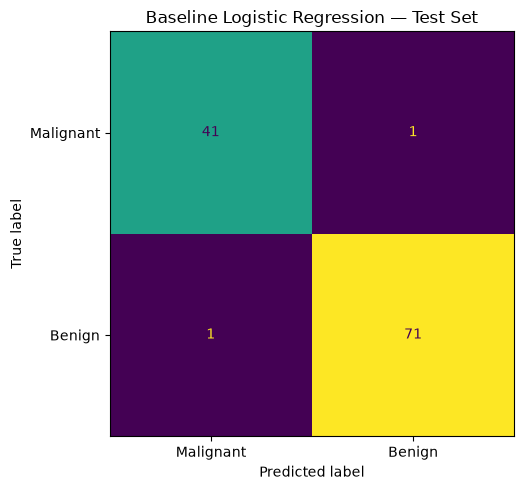

Saved final confusion matrix.


In [29]:
final_baseline = clone(logistic_pipeline)
final_baseline.fit(X_train, y_train)
final_baseline_predictions = final_baseline.predict(X_test)

cm = confusion_matrix(
    y_test,
    final_baseline_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

fig, ax = plt.subplots(figsize=(6, 5))
display.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("Baseline Logistic Regression — Test Set")
fig.tight_layout()

fig.savefig(
    results_dir / "final_logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
print("Saved final confusion matrix.")